In [3]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

Load Titanic Dataset
Clean Data and Encode the string to int

In [4]:
df = pd.read_csv("Titanic-Dataset.csv")

df = df.fillna(df.mode().iloc[0])
df.drop(["Name", "Ticket", "Cabin", "PassengerId"], axis=1, inplace=True)

le = LabelEncoder()
df['Sex'] = le.fit_transform(df['Sex'])
df['Embarked'] = le.fit_transform(df['Embarked'])

In [5]:
from sklearn.model_selection import train_test_split

Split training and testing data

In [6]:
x = df.drop("Survived", axis=1)
y = df["Survived"]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

Apply decesion tree classification
Calculate Accuracy Score and generate confusion matrix

In [8]:
model = DecisionTreeClassifier(random_state=42)
model.fit(x_train, y_train)
y_predict = model.predict(x_test)
accuracy = accuracy_score(y_test, y_predict)
confusion = confusion_matrix(y_test, y_predict)
print(accuracy)

0.7425373134328358


In [9]:
import matplotlib.pyplot as plt

Plot confusion matrix using matplotlib

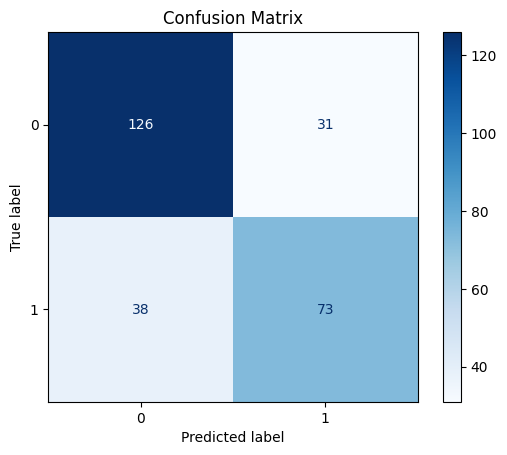

In [10]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion, display_labels=model.classes_)
disp.plot(cmap=plt.cm.Blues)

plt.title("Confusion Matrix")
plt.show()